# S&P 500 주가 데이터 분석 (2000~2019)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('S&P 500 과거 데이터.csv', encoding='utf-8-sig')
print(df.shape)
df.head()

(5000, 7)


,날짜,종가,시가,고가,저가,거래량,변동 %
0,2019- 11- 14,"3,096.60","3,090.80","3,098.20","3,083.30",NaN,0.08%
1,2019- 11- 13,"3,094.00","3,084.20","3,098.10","3,078.80",NaN,0.07%
2,2019- 11- 12,"3,091.80","3,089.30","3,102.60","3,084.70",NaN,0.16%
3,2019- 11- 11,"3,087.00","3,080.30","3,088.30","3,075.80",NaN,-0.20%
4,2019- 11- 08,"3,093.10","3,081.20","3,093.10","3,073.60",NaN,0.26%


## 1. 데이터 클렌징

In [2]:
df.info()
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   날짜      5000 non-null   str    
 1   종가      5000 non-null   str    
 2   시가      5000 non-null   str    
 3   고가      5000 non-null   str    
 4   저가      5000 non-null   str    
 5   거래량     0 non-null      float64
 6   변동 %    5000 non-null   str    
dtypes: float64(1), str(6)
memory usage: 273.6 KB
날짜         0
종가         0
시가         0
고가         0
저가         0
거래량     5000
변동 %       0
dtype: int64


In [3]:
# 날짜: '2019- 11- 14' 형태의 공백 제거 후 datetime 변환
df['날짜'] = pd.to_datetime(df['날짜'].str.replace(' ', '', regex=False), format='%Y-%m-%d')

# 가격 컬럼: 천단위 쉼표 제거 후 float 변환
price_cols = ['종가', '시가', '고가', '저가']
for c in price_cols:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '', regex=False), errors='coerce')

# 변동 %: '%' 제거 후 float
df['변동 %'] = pd.to_numeric(df['변동 %'].astype(str).str.replace('%', '', regex=False), errors='coerce')

# 거래량은 전부 비어 있으면 삭제
if df['거래량'].isna().all():
    df = df.drop(columns='거래량')

# 중복 제거, 결측 제거, 날짜 오름차순 정렬
df = df.drop_duplicates(subset='날짜').dropna(subset=['날짜', '종가'])
df = df.sort_values('날짜').set_index('날짜')

# 가격 논리 오류 점검 (고가 < 저가)
print('고가<저가 행 수:', (df['고가'] < df['저가']).sum())
print('기간:', df.index.min().date(), '~', df.index.max().date())
df.info()
df.head()

고가<저가 행 수: 0
기간: 2000-01-03 ~ 2019-11-14
<class 'pandas.DataFrame'>
DatetimeIndex: 5000 entries, 2000-01-03 to 2019-11-14
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   종가      5000 non-null   float64
 1   시가      5000 non-null   float64
 2   고가      5000 non-null   float64
 3   저가      5000 non-null   float64
 4   변동 %    5000 non-null   float64
dtypes: float64(5)
memory usage: 234.4 KB


,종가,시가,고가,저가,변동 %
날짜,,,,,
2000-01-03,1455.2,1469.2,1478.0,1438.4,-0.95
2000-01-04,1399.4,1455.2,1455.2,1397.4,-3.83
2000-01-05,1402.1,1399.4,1413.3,1377.7,0.19
2000-01-06,1403.5,1402.1,1411.9,1392.0,0.10
2000-01-07,1441.5,1403.5,1441.5,1400.5,2.71


## 2. 기본 통계

In [4]:
df.describe()

,종가,시가,고가,저가,변동 %
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,1565.181160,1564.990500,1573.893580,1555.375560,0.021970
std,574.248865,574.162272,574.935851,573.241574,1.192041
min,676.500000,679.300000,695.300000,666.800000,-9.040000
25%,1150.275000,1150.450000,1158.525000,1140.950000,-0.470000
50%,1358.200000,1358.050000,1366.950000,1347.000000,0.050000
75%,1973.375000,1974.275000,1983.375000,1965.150000,0.570000
max,3096.600000,3090.800000,3102.600000,3084.700000,11.590000


## 3. 종가 라인 그래프 (2000년 초 ~ 2019년 말)

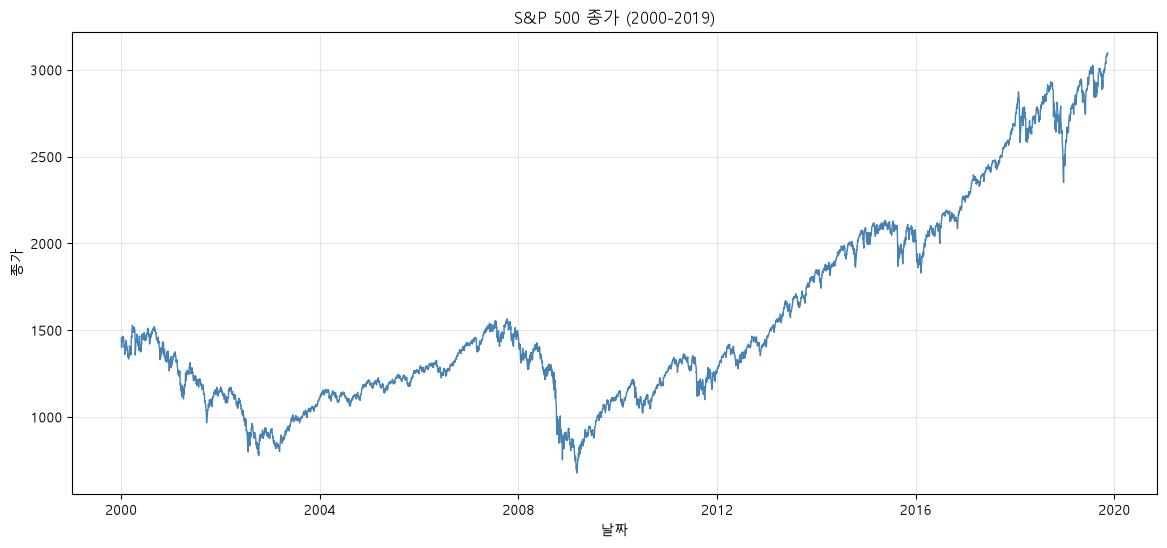

In [5]:
data = df.loc['2000-01-01':'2019-12-31']
plt.figure(figsize=(14, 6))
plt.plot(data.index, data['종가'], color='steelblue', linewidth=1)
plt.title('S&P 500 종가 (2000-2019)')
plt.xlabel('날짜')
plt.ylabel('종가')
plt.grid(True, alpha=0.3)
plt.show()

## 4. 이동평균 (50일, 200일)

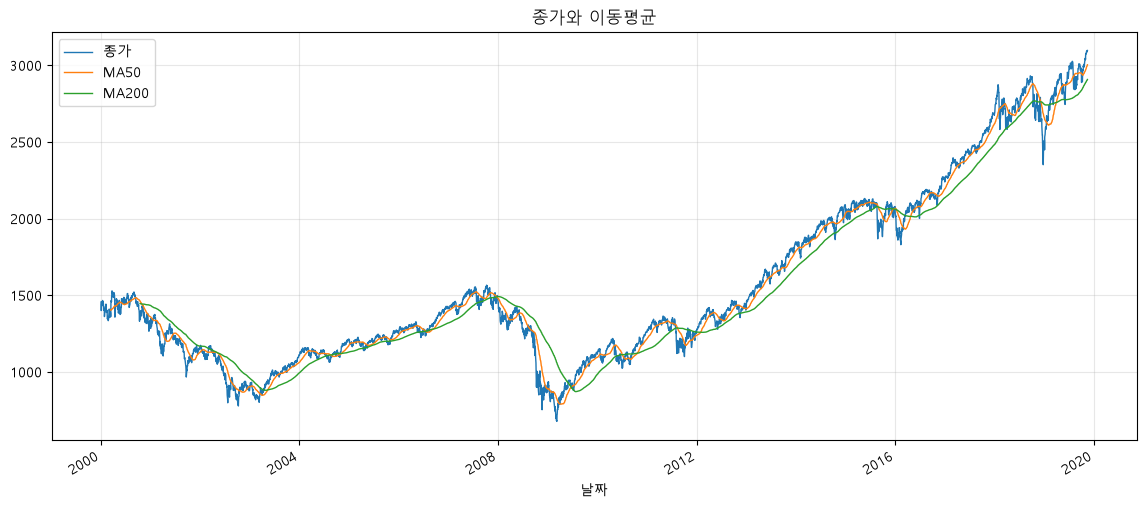

In [6]:
df['MA50'] = df['종가'].rolling(50).mean()
df['MA200'] = df['종가'].rolling(200).mean()
df[['종가', 'MA50', 'MA200']].plot(figsize=(14, 6), linewidth=1, title='종가와 이동평균')
plt.grid(True, alpha=0.3)
plt.show()

## 5. 연도별 분석 (연간 수익률, 최고/최저, 평균 변동성)

,시작종가,마지막종가,최고가,최저가,평균종가,변동성,연수익률(%)
날짜,,,,,,,
2000,1455.2,1320.3,1553.1,1254.1,1427.22,1.40,-9.27
2001,1283.3,1148.1,1383.4,944.8,1194.18,1.36,-10.54
2002,1154.7,879.8,1177.0,768.6,993.94,1.64,-23.81
2003,909.0,1111.9,1112.6,788.9,965.23,1.08,22.32
2004,1108.5,1211.9,1217.3,1060.7,1130.65,0.70,9.33
2005,1202.1,1248.3,1275.8,1136.2,1207.23,0.65,3.84
2006,1268.8,1418.3,1431.8,1219.3,1310.46,0.63,11.78
2007,1416.6,1468.4,1576.1,1364.0,1477.19,1.01,3.66
2008,1447.2,903.2,1471.8,741.0,1220.04,2.58,-37.59


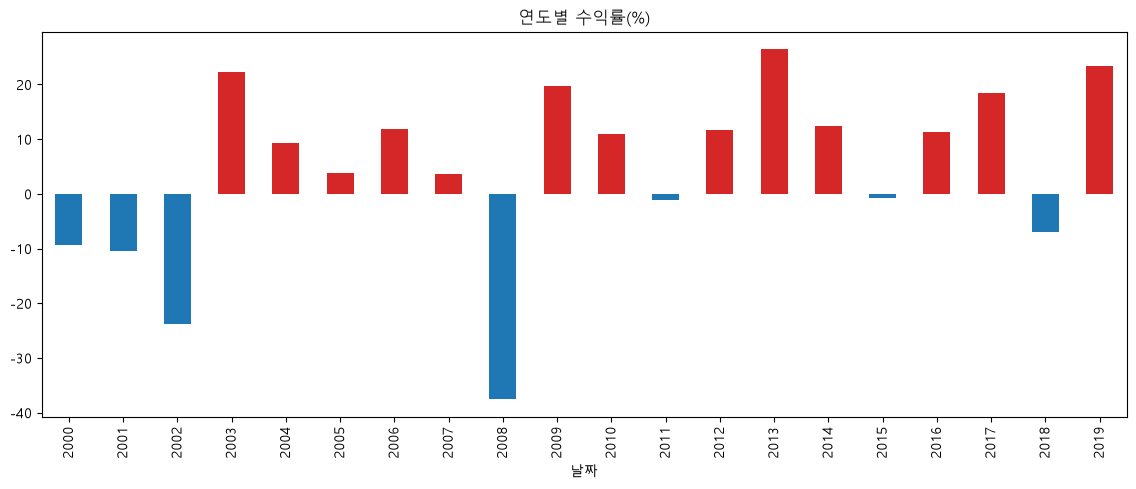

In [7]:
df['일간수익률'] = df['종가'].pct_change() * 100
yearly = df.groupby(df.index.year).agg(
    시작종가=('종가', 'first'), 마지막종가=('종가', 'last'),
    최고가=('고가', 'max'), 최저가=('저가', 'min'),
    평균종가=('종가', 'mean'), 변동성=('일간수익률', 'std'))
yearly['연수익률(%)'] = (yearly['마지막종가'] / yearly['시작종가'] - 1) * 100
display(yearly.round(2))
yearly['연수익률(%)'].plot(kind='bar', figsize=(14, 5), title='연도별 수익률(%)',
    color=np.where(yearly['연수익률(%)'] >= 0, 'tab:red', 'tab:blue'))
plt.show()

## 6. 월별 평균 수익률 및 요일 효과

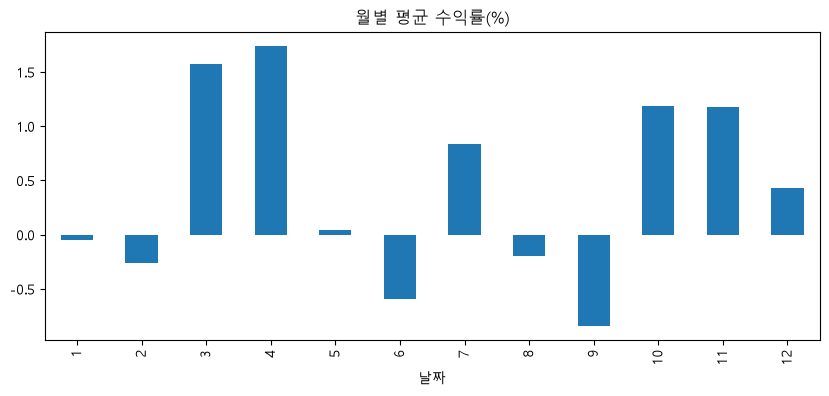

C:\Users\student\AppData\Local\Temp\ipykernel_22744\2883419287.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df.groupby(df.index.dayofweek)['일간수익률'].mean().rename(


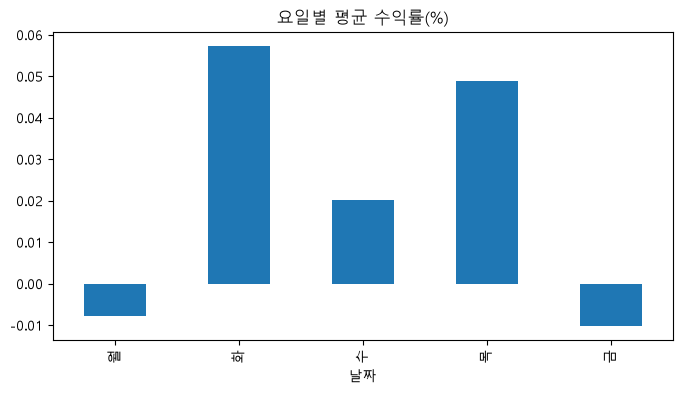

In [8]:
monthly = df['종가'].resample('ME').last().pct_change() * 100
monthly.groupby(monthly.index.month).mean().plot(kind='bar', figsize=(10, 4), title='월별 평균 수익률(%)')
plt.show()
df.groupby(df.index.dayofweek)['일간수익률'].mean().rename(
    {0: '월', 1: '화', 2: '수', 3: '목', 4: '금'}).plot(kind='bar', figsize=(8, 4), title='요일별 평균 수익률(%)')
plt.show()

## 7. 일간 수익률 분포와 극단값

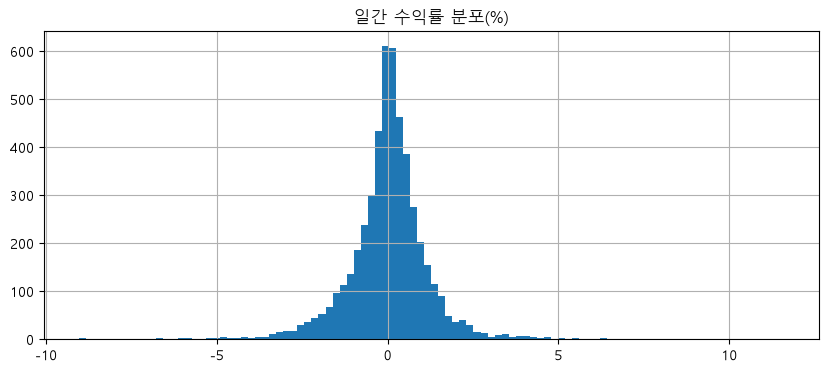

최대 상승일


날짜
2008-10-13    11.588078
2008-10-28    10.790435
2009-03-23     7.078725
2008-11-13     6.922445
2008-11-24     6.475000
Name: 일간수익률, dtype: float64

최대 하락일


날짜
2008-10-15   -9.038076
2008-12-01   -8.926579
2008-09-29   -8.788129
2008-10-09   -7.614986
2008-11-20   -6.719564
Name: 일간수익률, dtype: float64

In [9]:
df['일간수익률'].hist(bins=100, figsize=(10, 4))
plt.title('일간 수익률 분포(%)')
plt.show()
print('최대 상승일'); display(df['일간수익률'].nlargest(5))
print('최대 하락일'); display(df['일간수익률'].nsmallest(5))

## 8. 누적 최대 낙폭(Drawdown)과 금융위기 구간

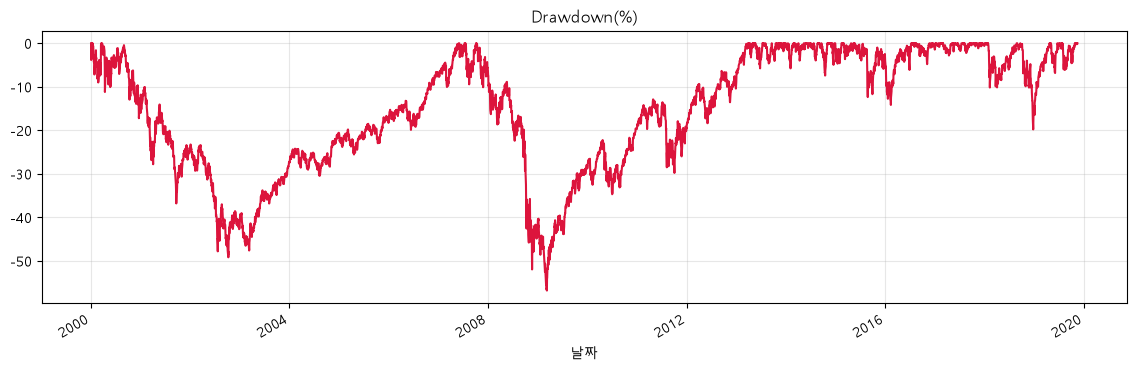

최대 낙폭: -56.78% (2009-03-09)


In [10]:
dd = (df['종가'] / df['종가'].cummax() - 1) * 100
dd.plot(figsize=(14, 4), color='crimson', title='Drawdown(%)')
plt.grid(True, alpha=0.3)
plt.show()
print('최대 낙폭: %.2f%% (%s)' % (dd.min(), dd.idxmin().date()))

## 9. 상관관계 및 롤링 변동성

,종가,시가,고가,저가,일간수익률
종가,1.000,1.000,1.00,1.000,0.024
시가,1.000,1.000,1.00,1.000,-0.001
고가,1.000,1.000,1.00,1.000,0.010
저가,1.000,1.000,1.00,1.000,0.013
일간수익률,0.024,-0.001,0.01,0.013,1.000


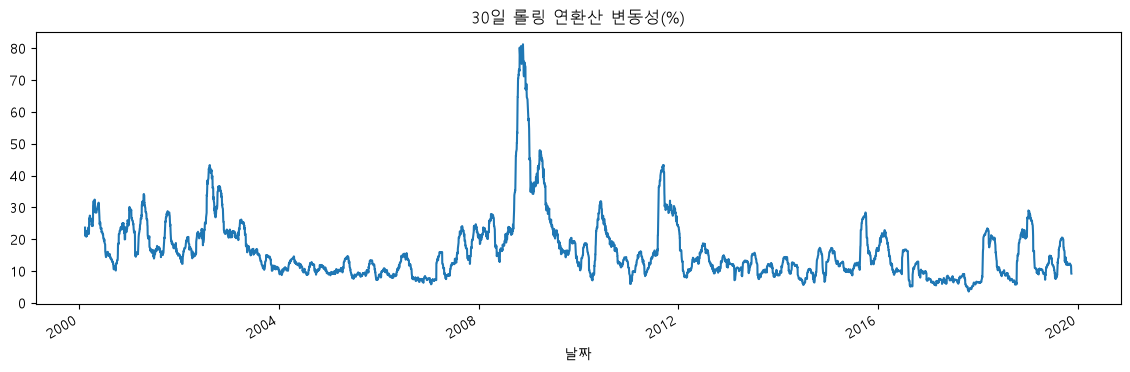

In [11]:
display(df[['종가', '시가', '고가', '저가', '일간수익률']].corr().round(3))
(df['일간수익률'].rolling(30).std() * np.sqrt(252)).plot(figsize=(14, 4), title='30일 롤링 연환산 변동성(%)')
plt.show()